# 8. Empirical claims: calibrating both models to a common real interest rate

**Question.** If I did not know the 4-state model existed, how would I calibrate the 2-state model, and would anything look wrong?

**Test.**
1. Measure the ~50-year average of Argentina's interest rate, in nominal and real terms.
2. Fix a common target for the equilibrium **real** risk-free rate, $r^* = 2\%$ per year, as proposed by the advisor.
3. Calibrate each model to that target with **one** free parameter, keeping every other parameter at its thesis value (Section 2, full Argentine calibration, $\eta=0.42$).
4. Ask whether either model needs a strange parameter value to hit the target, and whether either model makes strange predictions once calibrated.

**Discipline.**
- The only calibrated parameter is the discount rate $\rho$. In a Huggett economy, $\rho$ is the parameter that conventionally pins down $r^*$. Nothing else is changed.
- The solver is the same algorithm as notebooks `4.` and `5.`. Step 2 checks that it reproduces the thesis numbers before it is used.
- The conclusion is stated at the end, whichever way the evidence points.

In [1]:
import os, math, io
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import requests
from scipy.sparse import spdiags, eye, bmat, kron, csc_matrix
from scipy.sparse.linalg import spsolve

plt.rcParams.update({"font.family": "serif", "mathtext.fontset": "cm", "axes.grid": True,
                     "grid.color": "#e8e8e8", "legend.frameon": False})
MODEL_DATA = "data"                                    # repo data folder (lambdas, incomes)
DATA_DIR = os.path.join(MODEL_DATA, "interest_rates")  # interest-rate inputs and results of this notebook
os.makedirs(DATA_DIR, exist_ok=True)

## Step 1. The 50-year Argentine interest rate

**Source.** Global Macro Database (Müller, Xu, Lehbib & Chen, 2025), release `2026_09`, downloaded from the official release bucket. It splices national and international sources. Three series are used:

| GMD variable | Meaning | Coverage for ARG |
|---|---|---|
| `cbrate` | Central bank policy rate (BIS) | 1993–2025 only |
| `strate` | Short-term interest rate (CS2 / Bordo / ECLAC / OECD / IMF IFS, spliced) | 1970–2025 |
| `infl` | CPI inflation, % per year | full |

Argentina has had **no continuous policy ("target") rate for 50 years**. The BIS series starts in 1993 and changes instrument many times: LEBAC, repo corridor, LELIQ, and so on. Since July 2025 the BCRA has no policy rate. A 50-year window, 1976–2025, therefore has to use the short-term rate `strate`. The policy rate is reported for the years where it exists.

The ex-post real rate uses the exact Fisher relation, $r_t = (1+i_t)/(1+\pi_t)-1$. Forecast rows are dropped.

In [2]:
GMD_VERSION = "2026_09"
GMD_BASE = "https://gmd-releases.s3.ap-southeast-2.amazonaws.com/data/distribute"

def load_gmd_arg(var):
    # Download the GMD variable file once (cached locally) and keep Argentina, non-forecast rows
    path = os.path.join(DATA_DIR, f"{var}_{GMD_VERSION}.csv")
    if not os.path.exists(path):
        resp = requests.get(f"{GMD_BASE}/{var}_{GMD_VERSION}.csv", timeout=120)
        resp.raise_for_status()
        with open(path, "wb") as f:
            f.write(resp.content)
    df = pd.read_csv(path, low_memory=False)
    df = df[(df["ISO3"] == "ARG") & df[var].notna()]
    df = df[df["forecast"].fillna(0) == 0]
    return df.set_index("year")[[var, "source"]].rename(columns={"source": f"src_{var}"}).sort_index()

rates = (load_gmd_arg("strate")
         .join(load_gmd_arg("cbrate"), how="outer")
         .join(load_gmd_arg("infl"), how="outer"))
rates = rates.loc[1970:2025]
rates["real_strate"] = 100 * ((1 + rates["strate"] / 100) / (1 + rates["infl"] / 100) - 1)
rates["real_cbrate"] = 100 * ((1 + rates["cbrate"] / 100) / (1 + rates["infl"] / 100) - 1)
rates.to_csv(os.path.join(DATA_DIR, "argentina_rates_extract.csv"))
rates.loc[1976:2025, ["strate", "src_strate", "cbrate", "infl", "real_strate", "real_cbrate"]].round(2)

,strate,src_strate,cbrate,infl,real_strate,real_cbrate
year,,,,,,
1976,77.04,CS2,NaN,444.01,-67.46,NaN
1977,126.60,CS2,NaN,176.03,-17.91,NaN
1978,84.00,CS2,NaN,175.51,-33.21,NaN
1979,71.04,CS2,NaN,159.51,-34.09,NaN
1980,65.16,CS2,NaN,100.77,-17.73,NaN
1981,83.28,CS2,NaN,104.48,-10.37,NaN
1982,201.97,BORDO,NaN,164.78,14.05,NaN
1983,738.97,BORDO,NaN,343.81,89.04,NaN
1984,330.24,CS2,NaN,626.72,-40.80,NaN


In [3]:
def summarize(series_nom, y0, y1, label):
    d = rates.loc[y0:y1, [series_nom, "infl"]].dropna()
    real = 100 * ((1 + d[series_nom] / 100) / (1 + d["infl"] / 100) - 1)
    log_real = np.log1p(d[series_nom] / 100) - np.log1p(d["infl"] / 100)
    return {"series": label, "window": f"{y0}-{y1}", "n_years": len(d),
            "nominal mean %": d[series_nom].mean(), "nominal median %": d[series_nom].median(),
            "real mean %": real.mean(), "real median %": real.median(),
            "real geometric mean %": 100 * (np.exp(log_real.mean()) - 1),
            "share of years real > 0": (real > 0).mean()}

windows = [(1976, 2025), (1976, 1990), (1991, 2001), (2002, 2025), (1993, 2025)]
tab_rates = pd.DataFrame([summarize("strate", a, b, "short-term rate") for a, b in windows] +
                         [summarize("cbrate", 1993, 2025, "policy rate (BIS)"),
                          summarize("cbrate", 2002, 2025, "policy rate (BIS)")])
tab_rates.to_csv(os.path.join(DATA_DIR, "argentina_real_rate_summary.csv"), index=False)
tab_rates.round(2)

,series,window,n_years,nominal mean %,nominal median %,real mean %,real median %,real geometric mean %,share of years real > 0
0,short-term rate,1976-2025,50,71.86,27.25,-11.05,-5.12,-19.02,0.34
1,short-term rate,1976-1990,15,186.08,96.72,-27.01,-33.21,-43.43,0.27
2,short-term rate,1991-2001,11,14.41,9.12,2.05,6.66,0.30,0.82
3,short-term rate,2002-2025,24,26.80,19.96,-7.09,-5.12,-8.14,0.17
4,short-term rate,1993-2025,33,22.36,12.38,-2.82,-3.56,-3.91,0.39
5,policy rate (BIS),1993-2025,33,37.48,9.50,12.54,-4.19,-0.11,0.33
6,policy rate (BIS),2002-2025,24,26.33,18.40,-7.54,-7.03,-8.81,0.21


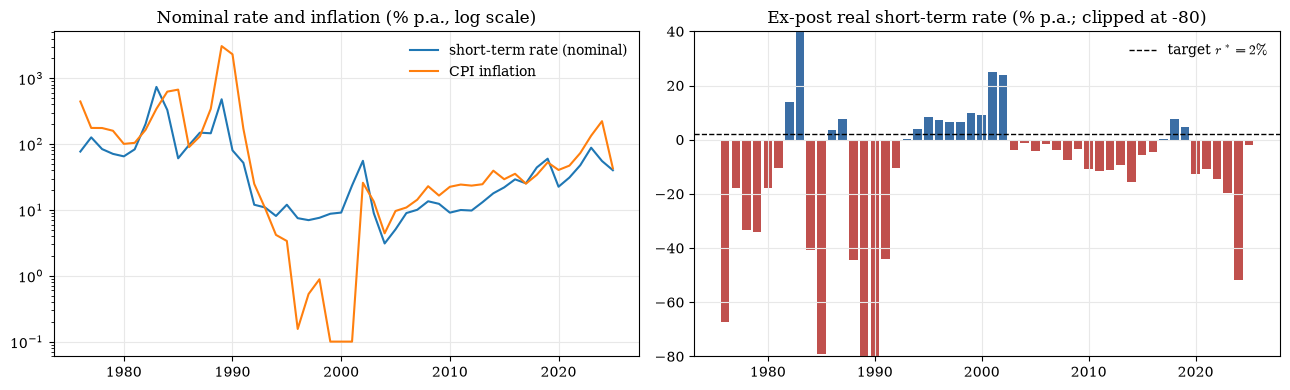

In [4]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
w = rates.loc[1976:2025]
ax[0].semilogy(w.index, w["strate"].clip(lower=0.1), label="short-term rate (nominal)")
ax[0].semilogy(w.index, w["infl"].clip(lower=0.1), label="CPI inflation")
ax[0].set_title("Nominal rate and inflation (% p.a., log scale)"); ax[0].legend()
ax[1].bar(w.index, w["real_strate"], color=np.where(w["real_strate"] > 0, "#3b6ea5", "#c0504d"))
ax[1].axhline(2, color="k", ls="--", lw=1, label="target $r^*=2\\%$")
ax[1].set_ylim(-80, 40); ax[1].set_title("Ex-post real short-term rate (% p.a.; clipped at -80)")
ax[1].legend(); plt.tight_layout(); plt.show()

### Step 1 result (read the table above)

- The 50-year **nominal** average is dominated by the 1975–1991 high-inflation and hyperinflation years. It is not a usable model target.
- The 50-year **ex-post real** short-term rate is **negative** on average, by mean, median and geometric mean. The only sub-period with an average real rate near $+2\%$ is Convertibility (1991–2001). 2002–2025 is also clearly negative, and so is the real policy rate.
- So the data do **not** directly support "$r^*=2\%$ is the 50-year Argentine average". A steady-state Huggett model cannot use a negative ex-post average, which reflects financial repression and surprise inflation, as the equilibrium return on a risk-free bond.
- The model target therefore stays at the advisor's $r^*=2\%$. It is below the 3% previously discussed and close to the Convertibility-era real average. This choice is an external calibration decision, not a data moment. All of what follows is conditional on it, and Step 8 checks other targets.

In [5]:
R_TARGET = 0.02

## Step 2. The model solver (same algorithm as notebooks 4 and 5) and a replication check

The function below is the solver from `4. equilibrium_2state_arg.ipynb` and `5. equilibrium_4state_arg.ipynb`, written once for $N$ states:
- implicit Euler with $\Delta=1000$, convergence at $10^{-6}$;
- upwind finite differences and the same boundary conditions at $a_{\min}$ and $a_{\max}$;
- borrowing premium $\theta_j$ when $a<0$;
- switching block $\Lambda\otimes I$, Fokker–Planck with one normalized row, and the same grid: $I=800$ on $[-0.099, 5]$.

The only addition is a validity flag. It is set when the HJB fails to converge or the density has negative mass, so such points are never used silently.

In [6]:
I_GRID, AMIN, AMAX = 800, -0.099, 5.0
a = np.linspace(AMIN, AMAX, I_GRID)
da = (AMAX - AMIN) / (I_GRID - 1)

def solve_given_r(r, rho, m, V_init=None, Delta=1000.0, maxit=400):
    z, gamma, tau, theta = m["z"], m["gamma"], m["tau"], m["theta"]
    I, N = len(a), len(z)
    zat = (1 - tau) * z
    zz = np.ones((I, 1)) * zat[None, :]
    aa = np.repeat(a[:, None], N, axis=1)
    R = r + theta[None, :] * (a < 0)[:, None]
    Lam = np.array(m["Lambda"], float).copy()
    np.fill_diagonal(Lam, 0.0); np.fill_diagonal(Lam, -Lam.sum(1))       # enforce row sums = 0
    Asw = kron(csc_matrix(Lam), eye(I), format="csc")
    if V_init is None:
        V = np.maximum(zz + r * aa, 1e-12) ** (1 - gamma) / ((1 - gamma) * rho)
    else:
        V = V_init.copy()
    dVf = np.zeros((I, N)); dVb = np.zeros((I, N)); converged = False
    for it in range(maxit):
        dVf[:-1] = (V[1:] - V[:-1]) / da
        dVf[-1] = np.maximum(zat + r * AMAX, 1e-12) ** (-gamma)
        dVb[1:] = (V[1:] - V[:-1]) / da
        dVb[0] = np.maximum(zat + (r + theta) * AMIN, 1e-12) ** (-gamma)
        cf = np.maximum(dVf, 1e-12) ** (-1 / gamma)
        cb = np.maximum(dVb, 1e-12) ** (-1 / gamma)
        ssf = zz + R * aa - cf; ssb = zz + R * aa - cb; c0 = zz + R * aa
        If = (ssf > 1e-14).astype(float); Ib = (ssb < -1e-14).astype(float); I0 = 1 - If - Ib
        c = cf * If + cb * Ib + c0 * I0
        util = np.maximum(c, 1e-12) ** (1 - gamma) / (1 - gamma)
        X = -np.minimum(ssb, 0) / da
        Y = -np.maximum(ssf, 0) / da + np.minimum(ssb, 0) / da
        Zc = np.maximum(ssf, 0) / da
        blocks = [spdiags(Y[:, j], 0, I, I) + spdiags(X[1:, j], -1, I, I)
                  + spdiags(np.hstack(([0.0], Zc[:-1, j])), 1, I, I) for j in range(N)]
        A = bmat([[blocks[i] if i == j else None for j in range(N)] for i in range(N)], format="csc") + Asw
        if np.max(np.abs(np.asarray(A.sum(axis=1)).ravel())) > 1e-7:
            # Same check as notebooks 4/5; here the point is flagged invalid instead of aborting
            return dict(V=V, c=c, g=None, adot=None, S=np.nan, valid=False, iters=it + 1)
        B = (1 / Delta + rho) * eye(N * I, format="csc") - A
        Vn = spsolve(B, util.T.ravel() + V.T.ravel() / Delta).reshape(N, I).T
        diff = np.max(np.abs(Vn - V)); V = Vn
        if diff < 1e-6:
            converged = True; break
    AT = A.T.tolil(); b = np.zeros(N * I); AT[0, :] = 0; AT[0, 0] = 1; b[0] = 1
    g = spsolve(AT.tocsr(), b).reshape(N, I).T
    g /= g.sum() * da
    valid = converged and (g.min() * da > -1e-8)
    return dict(V=V, c=c, g=g, adot=zz + R * aa - c, S=float((g * a[:, None]).sum() * da),
                valid=valid, iters=it + 1)

def find_equilibrium(rho, m, rmin, rmax, r0=0.03, tol_S=1e-5, max_iter=100):
    # Same bisection rule as notebooks 4/5: S>0 -> lower r, S<0 -> raise r
    r, V = r0, None
    for _ in range(max_iter):
        out = solve_given_r(r, rho, m, V_init=V)
        if out["S"] > tol_S:   rmax, r = r, 0.5 * (r + rmin)
        elif out["S"] < -tol_S: rmin, r = r, 0.5 * (r + rmax)
        else: return r, out, True
        V = out["V"]
    return r, out, False

### Model inputs, taken verbatim from the thesis

**2-state** (order: Informal, Formal):
- incomes $y=(0.418, 1)$; taxes $\tau=(0, 0.19)$; premium $\theta=(0.02, 0)$; risk aversion $\gamma=(0.30, 0.15)$ (thesis Table 1);
- hazards from the EPH generator ($\lambda_{IF}+\lambda_{FI}=0.91398$), split to give $\eta$.

**4-state** (order: IH, IL, FH, FL):
- incomes $y=(0.830, 0.220, 1, 0.321)$; taxes $\tau=(0,0,0.19,0.05)$; premium $\theta=(0.02,0.02,0,0)$; risk aversion $\gamma=(0.30,0.30,0.15,0.15)$;
- generators read at full precision from `data/lambda_matrix_4state_datadriven.csv` ($\eta=0.42$, thesis Table 3) and `data/lambda_matrix_4state_benchmark_eta20.csv` ($\eta=0.20$, Table 2).

> Note: the code cell for 2-state Section 2 in notebook 4 uses $\gamma_I=0.27$, but the thesis text and Table 1 say $0.30$. This notebook uses $0.30$ so that the two models share the same preferences. Step 8 reruns the 2-state model with $0.27$.

In [7]:
def read_generator(fname, order):
    # Read a generator CSV exported by the R scripts and reorder rows/cols by state label
    df = pd.read_csv(os.path.join(MODEL_DATA, fname), index_col=0)
    df.index = df.index.str.strip(); df.columns = df.columns.str.strip()
    return df.loc[order, order].to_numpy(float)

L2_DATA = read_generator("lambda_matrix_2state_datadriven.csv", ["I", "F"])
TOTAL_HAZARD_2S = L2_DATA[0, 1] + L2_DATA[1, 0]        # lam_IF + lam_FI from EPH
print(f"2-state data generator: lam_IF={L2_DATA[0,1]:.6f}, lam_FI={L2_DATA[1,0]:.6f}, total={TOTAL_HAZARD_2S:.6f}")

def lambda_2state(eta, s=TOTAL_HAZARD_2S):
    # row = from, col = to ; states (I, F); stationary informal share = eta (same split as notebook 4)
    return np.array([[0.0, (1 - eta) * s], [eta * s, 0.0]])

ORDER4 = ["IH", "IL", "FH", "FL"]   # model order used in notebook 5
LAMBDA4_ETA42 = read_generator("lambda_matrix_4state_datadriven.csv", ORDER4)       # thesis Table 3
LAMBDA4_ETA20 = read_generator("lambda_matrix_4state_benchmark_eta20.csv", ORDER4)  # thesis Table 2

def model_2state(eta=0.42, gamma_I=0.30, tau_F=0.19):
    return dict(name="2-state", labels=["I", "F"], informal=[0], formal=[1],
                z=np.array([0.418, 1.0]), gamma=np.array([gamma_I, 0.15]),
                tau=np.array([0.0, tau_F]), theta=np.array([0.02, 0.0]), Lambda=lambda_2state(eta))

def model_4state(eta=0.42, tau_FH=0.19, tau_FL=0.05):
    L = {0.42: LAMBDA4_ETA42, 0.20: LAMBDA4_ETA20}[eta]
    return dict(name="4-state", labels=["IH", "IL", "FH", "FL"], informal=[0, 1], formal=[2, 3],
                z=np.array([0.82979213, 0.219700297, 1.0, 0.321119145]),
                gamma=np.array([0.30, 0.30, 0.15, 0.15]),
                tau=np.array([0.0, 0.0, tau_FH, tau_FL]), theta=np.array([0.02, 0.02, 0.0, 0.0]), Lambda=L)

def stationary(L):
    L = np.array(L, float).copy(); np.fill_diagonal(L, 0); np.fill_diagonal(L, -L.sum(1))
    w, v = np.linalg.eig(L.T); p = np.real(v[:, np.argmin(np.abs(w))]); return p / p.sum()

for eta in (0.20, 0.42):
    p = stationary(model_4state(eta)["Lambda"])
    print(f"4-state eta={eta}: stationary (IH,IL,FH,FL) = {np.round(p,4)}, informal = {p[:2].sum():.4f}, "
          f"phi = IH/(IH+IL) = {p[0]/p[:2].sum():.3f}")

2-state data generator: lam_IF=0.684364, lam_FI=0.229618, total=0.913981
4-state eta=0.2: stationary (IH,IL,FH,FL) = [0.0368 0.1632 0.556  0.244 ], informal = 0.2000, phi = IH/(IH+IL) = 0.184
4-state eta=0.42: stationary (IH,IL,FH,FL) = [0.0772 0.3428 0.4031 0.1769], informal = 0.4200, phi = IH/(IH+IL) = 0.184


### Replication check: rerun thesis cases at $\rho=0.05$ and compare with the printed outputs of notebooks 4 and 5

In [8]:
checks = [
    ("2-state Sec.2, gamma_I=0.27, eta=0.42", model_2state(0.42, gamma_I=0.27), 0.01, 0.10, 0.020229),
    ("2-state Sec.2, gamma_I=0.27, eta=0.20", model_2state(0.20, gamma_I=0.27), 0.01, 0.10, 0.033046),
    ("4-state Sec.1 (tau=0.19 all, gamma=0.15, theta=0), eta=0.42",
         dict(model_4state(0.42), tau=np.full(4, 0.19), gamma=np.full(4, 0.15), theta=np.zeros(4)), 0.0005, 0.10, 0.018977),
    ("4-state Sec.2, eta=0.20", model_4state(0.20), 0.0005, 0.10, 0.010061),
]
rows = []
for lab, m, lo, hi, thesis in checks:
    r, out, ok = find_equilibrium(0.05, m, lo, hi)
    rows.append({"case": lab, "r* here": r, "r* thesis/notebook": thesis, "abs diff": abs(r - thesis), "cleared": ok})
pd.DataFrame(rows)

,case,r* here,r* thesis/notebook,abs diff,cleared
0,"2-state Sec.2, gamma_I=0.27, eta=0.42",0.020229,0.020229,4.921875e-07,True
1,"2-state Sec.2, gamma_I=0.27, eta=0.20",0.033046,0.033046,2.646484e-07,True
2,"4-state Sec.1 (tau=0.19 all, gamma=0.15, theta...",0.018977,0.018977,1.118164e-07,True
3,"4-state Sec.2, eta=0.20",0.010061,0.010061,1.479492e-07,True


If the absolute differences above are $\approx 10^{-5}$ or smaller (the bisection tolerance), the solver and inputs reproduce the thesis.

## Step 3. Starting point: each model at the thesis discount rate $\rho = 0.05$

Under the full calibration at $\eta=0.42$, solve for $r^*$ in each model with the lower bound on $r$ **removed** (negative rates allowed), so the true market-clearing rate is reported rather than a bound.

In [9]:
base = {}
for m in (model_2state(0.42), model_4state(0.42)):
    r, out, ok = find_equilibrium(0.05, m, rmin=-0.05, rmax=0.10, r0=0.02)
    base[m["name"]] = r
    print(f"{m['name']}: rho=0.05 -> r* = {100*r:.3f}%  (cleared={ok}, valid={out['valid']})")

2-state: rho=0.05 -> r* = 1.587%  (cleared=True, valid=True)


4-state: rho=0.05 -> r* = -0.764%  (cleared=True, valid=True)


## Step 4. Calibrate $\rho$ in each model so that $r^* = 2\%$

At $r = 2\%$ fixed, aggregate bond holdings $S(\rho)$ fall as households become less patient. Solve $S(0.02;\rho)=0$ by bisection over $\rho$. By construction, the calibrated economy has $r^*=2\%$; Step 5 checks this independently.

First, trace $S(0.02;\rho)$ on a grid. This shows the root is bracketed and unique, and flags any numerically invalid points.

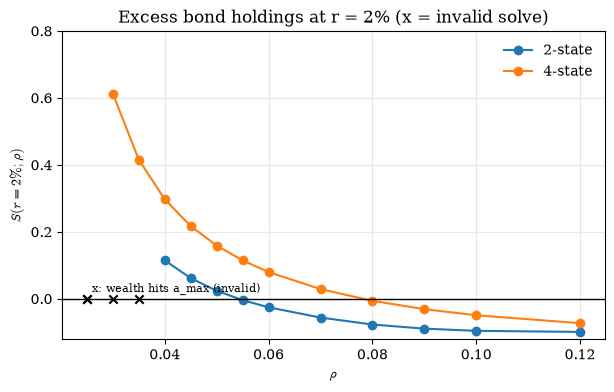

model,2-state,4-state
rho,,
0.025,NaN,NaN
0.030,NaN,0.6127
0.035,NaN,0.4150
0.040,0.1146,0.2968
0.045,0.0615,0.2169
0.050,0.0238,0.1588
0.055,-0.0042,0.1145
0.060,-0.0256,0.0798
0.070,-0.0561,0.0289


In [10]:
rho_grid = np.array([0.025, 0.03, 0.035, 0.04, 0.045, 0.05, 0.055, 0.06, 0.07, 0.08, 0.09, 0.10, 0.12])
scan = []
for mk in (model_2state, model_4state):
    m = mk(0.42)
    for rho in rho_grid:
        out = solve_given_r(R_TARGET, rho, m)
        scan.append({"model": m["name"], "rho": rho, "S(r=2%)": out["S"], "valid": out["valid"], "HJB iters": out["iters"]})
scan = pd.DataFrame(scan)

fig, ax = plt.subplots(figsize=(7, 4))
for name, d in scan.groupby("model"):
    dv = d[d["valid"]]
    ax.plot(dv["rho"], dv["S(r=2%)"], "o-", label=name)
    ax.scatter(d.loc[~d["valid"], "rho"], np.zeros((~d["valid"]).sum()), marker="x", color="k")
ax.text(0.026, 0.02, "x: wealth hits a_max (invalid)", fontsize=8)
ax.axhline(0, color="k", lw=1); ax.set_xlabel(r"$\rho$"); ax.set_ylabel(r"$S(r=2\%;\rho)$")
ax.set_ylim(-0.12, 0.8); ax.legend(); ax.set_title("Excess bond holdings at r = 2% (x = invalid solve)")
plt.show()
scan.pivot(index="rho", columns="model", values="S(r=2%)").round(4)

In [11]:
def bracket_rho(m, r_target, step=0.005, rho_max=0.30):
    # Walk up from just above r_target: lo = last VALID rho with S>0, hi = first rho with S<0
    lo, rho = None, r_target + step
    while rho <= rho_max:
        out = solve_given_r(r_target, rho, m)
        if out["valid"] and out["S"] > 0: lo = rho
        elif out["valid"] and out["S"] < 0:
            assert lo is not None, "no valid rho with S>0 below the root"
            return lo, rho
        rho += step
    raise RuntimeError("root not bracketed")

def calibrate_rho(m, r_target=R_TARGET, tol=1e-7, max_iter=60):
    lo, hi = bracket_rho(m, r_target)
    for _ in range(max_iter):
        mid = 0.5 * (lo + hi); out = solve_given_r(r_target, mid, m)
        assert out["valid"], f"invalid solve at rho={mid}"
        if out["S"] > 0: lo = mid
        else: hi = mid
        if hi - lo < tol: break
    return 0.5 * (lo + hi)

rho_cal = {}
for mk in (model_2state, model_4state):
    m = mk(0.42); rho_cal[m["name"]] = calibrate_rho(m)

tab_rho = pd.DataFrame({"calibrated rho": rho_cal,
              "annual discount factor beta = exp(-rho)": {k: np.exp(-v) for k, v in rho_cal.items()},
              "quarterly beta": {k: np.exp(-v / 4) for k, v in rho_cal.items()},
              "rho - r* (impatience gap)": {k: v - R_TARGET for k, v in rho_cal.items()}})
tab_rho.to_csv(os.path.join(DATA_DIR, "calibration_rho_rstar2.csv"))
tab_rho.round(4)

,calibrated rho,annual discount factor beta = exp(-rho),quarterly beta,rho - r* (impatience gap)
2-state,0.0542,0.9473,0.9866,0.0342
4-state,0.0780,0.9250,0.9807,0.0580


**How to judge $\rho$.** Annual $\rho$ between about 0.02 and 0.06 ($\beta\approx 0.94$–$0.98$) is the usual range for advanced-economy Huggett/Aiyagari models. Emerging-market models often use more impatient households: quarterly $\beta\approx 0.97$–$0.98$, i.e. annual $\rho\approx 0.08$–$0.12$ (e.g. Aguiar & Gopinath 2007; Neumeyer & Perri 2005). The model also requires $\rho > r^*$. A value is called "strange" here only if it falls outside these ranges.

## Step 5. Verify: re-solve the full equilibrium at the calibrated $\rho$

In [12]:
cal = {}
for mk in (model_2state, model_4state):
    m = mk(0.42)
    r, out, ok = find_equilibrium(rho_cal[m["name"]], m, rmin=-0.05, rmax=0.10, r0=0.03)
    cal[m["name"]] = dict(m=m, r=r, out=out)
    print(f"{m['name']}: rho={rho_cal[m['name']]:.5f} -> r* = {100*r:.4f}%  cleared={ok} valid={out['valid']}  "
          f"mass at a>4: {out['g'][a>4].sum()*da:.1e}")

2-state: rho=0.05416 -> r* = 2.0000%  cleared=True valid=True  mass at a>4: -2.3e-17
4-state: rho=0.07796 -> r* = 2.0000%  cleared=True valid=True  mass at a>4: 3.7e-17


## Step 6. Predictions of each calibrated model at $\eta = 0.42$

Both models now have the same $r^*=2\%$ and the same $\eta$. Compare what each predicts about who borrows, who is at the constraint, and how wealth splits between sectors.

In [13]:
def moments(m, out, r):
    g, c, adot = out["g"], out["c"], out["adot"]
    mass = g.sum(0) * da
    inf, frm = m["informal"], m["formal"]
    row = {"r* %": 100 * r,
           "borrowers mass (a<0)": (g[a < 0].sum()) * da,
           "mass at borrowing limit (first grid pt)": g[0].sum() * da,
           "informal: share borrowing": g[a < 0][:, inf].sum() * da / mass[inf].sum(),
           "formal: share borrowing": g[a < 0][:, frm].sum() * da / mass[frm].sum(),
           "informal mean wealth": (g[:, inf] * a[:, None]).sum() * da / mass[inf].sum(),
           "formal mean wealth": (g[:, frm] * a[:, None]).sum() * da / mass[frm].sum(),
           "informal mean consumption": (g[:, inf] * c[:, inf]).sum() * da / mass[inf].sum(),
           "formal mean consumption": (g[:, frm] * c[:, frm]).sum() * da / mass[frm].sum(),
           "gross debt / mean after-tax income": (g * np.maximum(-a, 0)[:, None]).sum() * da
                                                 / (mass * (1 - m["tau"]) * m["z"]).sum()}
    for j, lab in enumerate(m["labels"]):
        row[f"[{lab}] mass"] = mass[j]
        row[f"[{lab}] mean wealth"] = (g[:, j] * a).sum() * da / mass[j]
        row[f"[{lab}] share borrowing"] = g[a < 0, j].sum() * da / mass[j]
    return row

tab_cal = pd.DataFrame({k: moments(v["m"], v["out"], v["r"]) for k, v in cal.items()})
tab_cal.to_csv(os.path.join(DATA_DIR, "calibrated_moments_eta042.csv"))
tab_cal.round(4)

,2-state,4-state
r* %,2.0000,2.0000
borrowers mass (a<0),0.4911,0.5219
mass at borrowing limit (first grid pt),0.2340,0.2191
informal: share borrowing,0.8605,0.7584
formal: share borrowing,0.2235,0.3506
informal mean wealth,-0.0659,-0.0411
formal mean wealth,0.0477,0.0298
informal mean consumption,0.4754,0.3526
formal mean consumption,0.7674,0.6401
gross debt / mean after-tax income,0.0557,0.0714


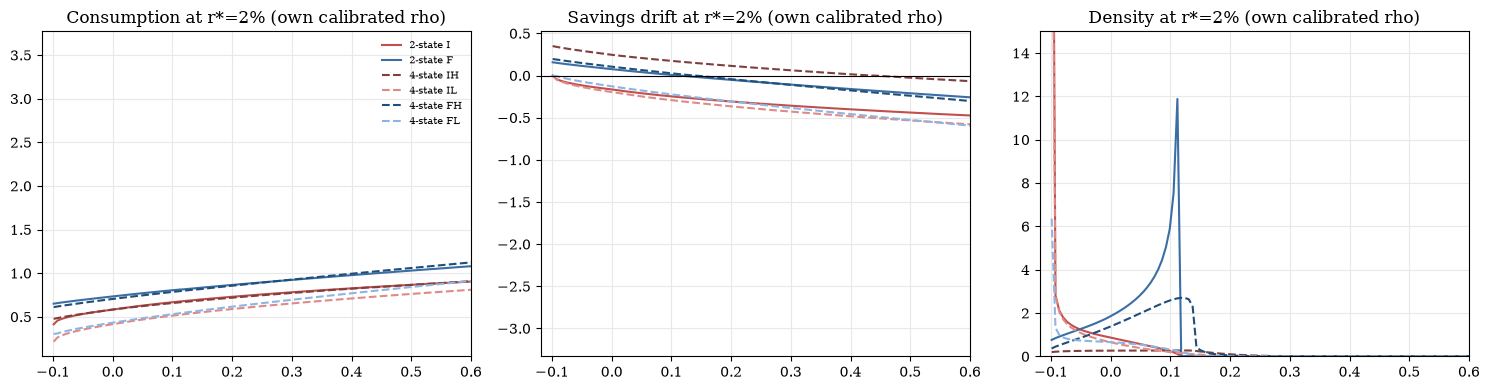

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
cols = {"I": "#c0504d", "F": "#3b6ea5", "IH": "#7f3f3e", "IL": "#e08a87", "FH": "#1f4e79", "FL": "#8db4e2"}
for k, v in cal.items():
    m, out = v["m"], v["out"]; ls = "-" if k == "2-state" else "--"
    for j, lab in enumerate(m["labels"]):
        ax[0].plot(a, out["c"][:, j], ls, color=cols[lab], label=f"{k} {lab}")
        ax[1].plot(a, out["adot"][:, j], ls, color=cols[lab], label=f"{k} {lab}")
        ax[2].plot(a, out["g"][:, j], ls, color=cols[lab], label=f"{k} {lab}")
for x, t in zip(ax, ["Consumption", "Savings drift", "Density"]):
    x.set_xlim(AMIN - 0.02, 0.6); x.set_title(f"{t} at r*=2% (own calibrated rho)")
ax[1].axhline(0, color="k", lw=0.8); ax[2].set_ylim(0, 15); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()

## Step 7. The counterfactual dimension: same experiment, each model at its own calibration

Hold each model's calibrated $\rho$ fixed and move the economy to the low-informality benchmark, $\eta=0.20$. This is the formalization counterfactual in thesis Sections 4.3–4.4. The question is whether the two models, both calibrated to the same $r^*$, predict **different signs** for the response of $r^*$ and of the borrowers mass. That would be a disagreement no data on the status-quo $r^*$ could resolve.

In [15]:
cf = []
for mk in (model_2state, model_4state):
    name = mk(0.42)["name"]; rho = rho_cal[name]
    for eta in (0.42, 0.20):
        m = mk(eta)
        r, out, ok = find_equilibrium(rho, m, rmin=-0.05, rmax=0.15, r0=0.03)
        mo = moments(m, out, r)
        cf.append({"model": name, "rho": rho, "eta": eta, "r* %": 100 * r, "cleared": ok and out["valid"],
                   "borrowers mass": mo["borrowers mass (a<0)"],
                   "mass at limit": mo["mass at borrowing limit (first grid pt)"],
                   "informal share borrowing": mo["informal: share borrowing"],
                   "formal share borrowing": mo["formal: share borrowing"]})
cf = pd.DataFrame(cf)
cf.to_csv(os.path.join(DATA_DIR, "counterfactual_eta_calibrated.csv"), index=False)
delta = (cf[cf.eta == 0.20].set_index("model")[["r* %", "borrowers mass", "mass at limit"]]
         - cf[cf.eta == 0.42].set_index("model")[["r* %", "borrowers mass", "mass at limit"]])
display(cf.round(4)); print("Change when eta goes 0.42 -> 0.20 (formalization):"); display(delta.round(4))

,model,rho,eta,r* %,cleared,borrowers mass,mass at limit,informal share borrowing,formal share borrowing
0,2-state,0.0542,0.42,2.0000,True,0.4911,0.2340,0.8605,0.2235
1,2-state,0.0542,0.20,3.4768,True,0.3714,0.1069,0.9013,0.2389
2,4-state,0.0780,0.42,2.0000,True,0.5219,0.2191,0.7584,0.3506
3,4-state,0.0780,0.20,3.7811,True,0.4820,0.1635,0.8027,0.4019


Change when eta goes 0.42 -> 0.20 (formalization):


,r* %,borrowers mass,mass at limit
model,,,
2-state,1.4768,-0.1197,-0.1271
4-state,1.7811,-0.0398,-0.0556


## Step 8. Robustness of the calibration result

1. **Target.** Calibrate $\rho$ for $r^*\in\{1\%, 1.5\%, 2\%, 2.5\%\}$. Does the ranking $\rho_{4s}$ vs $\rho_{2s}$ depend on the 2% choice?
2. **2-state with $\gamma_I=0.27$**, the value actually in notebook 4's code.
3. **Calibrate at $\eta=0.20$ instead of $0.42$**, to check whether the gap between models is driven by the size of the informal sector.

In [16]:
rob = []
for rt in (0.01, 0.015, 0.02, 0.025):
    for mk in (model_2state, model_4state):
        m = mk(0.42)
        rob.append({"target r*": rt, "model": m["name"], "rho": calibrate_rho(m, r_target=rt)})
rob = pd.DataFrame(rob).pivot(index="target r*", columns="model", values="rho")
rob["rho_4s - rho_2s"] = rob["4-state"] - rob["2-state"]
rob.to_csv(os.path.join(DATA_DIR, "calibration_rho_by_target.csv"))
display(rob.round(4))

extra = {
    "2-state, gamma_I=0.27, eta=0.42": calibrate_rho(model_2state(0.42, gamma_I=0.27)),
    "2-state, eta=0.20": calibrate_rho(model_2state(0.20)),
    "4-state, eta=0.20": calibrate_rho(model_4state(0.20)),
}
pd.Series(extra, name="rho for r*=2%").round(4)

model,2-state,4-state,rho_4s - rho_2s
target r*,,,
0.010,0.0441,0.0678,0.0238
0.015,0.0491,0.0729,0.0238
0.020,0.0542,0.0780,0.0238
0.025,0.0592,0.0830,0.0238


2-state, gamma_I=0.27, eta=0.42    0.0498
2-state, eta=0.20                  0.0393
4-state, eta=0.20                  0.0600
Name: rho for r*=2%, dtype: float64

## Step 9. Mechanism check: why do the two models need different $\rho$?

At a common $\rho$ and $r$, compare the bond position each model generates. The 4-state model has more precautionary or savings motives if, at the same $(\rho, r)$, it wants to hold more bonds. The decomposition by state shows where those extra savings come from.

In [17]:
mech = []
for mk in (model_2state, model_4state):
    m = mk(0.42); out = solve_given_r(R_TARGET, 0.05, m); g = out["g"]
    for j, lab in enumerate(m["labels"]):
        mass = g[:, j].sum() * da
        mech.append({"model": m["name"], "state": lab, "after-tax income": (1 - m["tau"][j]) * m["z"][j],
                     "mass": mass, "net bonds (contribution to S)": (g[:, j] * a).sum() * da,
                     "mean wealth": (g[:, j] * a).sum() * da / mass,
                     "exit rate (1/expected duration)": np.delete(np.array(m["Lambda"])[j], j).sum()})
mech = pd.DataFrame(mech)
print("Aggregate S at rho=0.05, r=2%:", mech.groupby("model")["net bonds (contribution to S)"].sum().round(4).to_dict())
mech.round(4)

Aggregate S at rho=0.05, r=2%: {'2-state': 0.0238, '4-state': 0.1588}


,model,state,after-tax income,mass,net bonds (contribution to S),mean wealth,exit rate (1/expected duration)
0,2-state,I,0.4180,0.4200,-0.0228,-0.0542,0.5301
1,2-state,F,0.8100,0.5800,0.0465,0.0802,0.3839
2,4-state,IH,0.8298,0.0772,0.0150,0.1947,3.1544
3,4-state,IL,0.2197,0.3428,0.0065,0.0189,0.9843
4,4-state,FH,0.8100,0.4031,0.1144,0.2838,0.9087
5,4-state,FL,0.3051,0.1769,0.0228,0.1291,2.7836


## Step 10. Conclusion

The cell below prints the numbers the conclusion depends on, so the text can be checked against them.

In [18]:
print(f"50y (1976-2025) ex-post real short rate: mean {tab_rates.iloc[0]['real mean %']:.1f}%, "
      f"median {tab_rates.iloc[0]['real median %']:.1f}%, 1991-2001 mean {tab_rates.iloc[2]['real mean %']:.1f}%")
for k in rho_cal:
    print(f"{k}: rho for r*=2% = {rho_cal[k]:.4f} (beta={np.exp(-rho_cal[k]):.3f}); at rho=0.05 r* = {100*base[k]:.2f}%")
print(delta.round(4))

50y (1976-2025) ex-post real short rate: mean -11.1%, median -5.1%, 1991-2001 mean 2.0%
2-state: rho for r*=2% = 0.0542 (beta=0.947); at rho=0.05 r* = 1.59%
4-state: rho for r*=2% = 0.0780 (beta=0.925); at rho=0.05 r* = -0.76%
           r* %  borrowers mass  mass at limit
model                                         
2-state  1.4768         -0.1197        -0.1271
4-state  1.7811         -0.0398        -0.0556


### What the evidence says (numbers from Steps 1–9 above)

**1. The 50-year rate does not give 2%.**
- Argentina's 1976–2025 ex-post real short-term rate is negative: mean −11.1%, median −5.1%, geometric mean −19.0%. It is positive in only 34% of years.
- The only sub-period averaging about +2% is Convertibility, 1991–2001 (mean 2.05%).
- A policy rate exists only from 1993, and its real value is also negative on average after 2002.
- So $r^*=2\%$ is an external calibration choice. It matches the Convertibility average, not the 50-year average, and the thesis should say so.

**2. The hypothesis "the 2-state model needs a strange parameter to imply $r^*=2\%$" is NOT supported. The opposite is closer to true.**
- 2-state: $\rho=0.054$ ($\beta=0.947$ annual). This is a textbook value. At the thesis $\rho=0.05$ it already gives $r^*=1.6\%$.
- 4-state: $\rho=0.078$ ($\beta=0.925$ annual, $0.981$ quarterly). At the thesis $\rho=0.05$ it gives $r^*=-0.76\%$.
- The gap $\rho_{4s}-\rho_{2s}=0.024$ is the same for every target from 1% to 2.5%. With the code's $\gamma_I=0.27$ the 2-state needs $\rho=0.050$, so the gap is not driven by $\gamma_I$.
- Neither value is strange by emerging-market standards: quarterly $\beta\approx0.98$ is the usual value in Aguiar–Gopinath and Neumeyer–Perri. So neither model is ruled out on parameter grounds.
- The 4-state model is the one that needs more impatience. The reason is not mainly the IH group (Step 9). At a common $(\rho, r)$, the extra bond demand in the 4-state model comes overwhelmingly from **high-income formal** workers: FH net bonds are 0.114, against 0.047 for the 2-state formal group. FH workers face a frequent, large downside to FL income (0.32), so they hold large precautionary savings. IH contributes only 0.015.

**3. Predictions at the common calibration ($\eta=0.42$, $r^*=2\%$) look reasonable in both models.**
- Borrowers mass: 0.49 (2-state) versus 0.52 (4-state). Mass at the borrowing limit: 0.23 versus 0.22.
- Both models predict that informal households borrow more than formal ones.
- The 4-state model adds that FL workers mostly borrow (66%) while IH workers mostly save (33% borrowing).
- No prediction of either model is implausible, and wealth and borrowing are not observed in the EPH, so these moments cannot discriminate between the models with the thesis data.

**4. Formalization counterfactual ($\eta$: 0.42 → 0.20, each model at its own $\rho$).**
- Both models predict the **same signs**: $r^*$ rises (+1.5 pp in the 2-state, +1.8 pp in the 4-state) and the borrowers mass falls.
- They differ in magnitude. The fall in the borrowers mass is −0.120 in the 2-state model and −0.040 in the 4-state model, about one-third. The fall in mass at the constraint is −0.127 versus −0.056.
- The thesis's "sign reversal in the borrowers mass" (Section 4.4) therefore **does not survive** a common-$r^*$ calibration. In the thesis, the 4-state equilibrium at $\eta=0.42$ and $\rho=0.05$ never cleared the bond market: bisection stopped at the lower bound $r=0.0005$ with $S=+0.03$ (notebook 5 output). The reported reversal comes from that non-equilibrium point.

**5. What the thesis can defensibly claim after this test.**
- *Not supported:* the 2-state model needs implausible parameters; the 2-state model "overestimates $r^*$" (once both are calibrated to the observed $r^*$, levels are equal by construction); the borrowers-mass sign reversal; the claim that IH workers are what depresses $r^*$.
- *Supported:* conditional on the same observed $r^*$ and $\eta$, the two models imply different impatience. The 4-state model implies a much smaller response of financial constraints to formalization, about one-third of the 2-state response, and a somewhat larger $r^*$ response. This is a magnitude disagreement in the counterfactual, which is the kind of difference that matters for policy evaluation.
- *Natural next step:* repeat the Case A/B/C reform comparison of Section 4.6 with each model at its own calibrated $\rho$. The welfare and revenue gaps reported in the thesis were also computed at a common $\rho=0.05$, and at $\eta=0.42$ the 4-state economy did not clear there.